SQLite Databases and Python

This project explores the World SQLite database, identifies the most recently independent country, adds a newer country and two cities to the database, and uses country data to create a visualization.

In [1]:
import sqlite3

# Connect to the World database
conn = sqlite3.connect("world.sqlite")

# Find the country with the most recent independence year
query = """
SELECT Name, IndepYear
FROM country
WHERE IndepYear IS NOT NULL
ORDER BY IndepYear DESC
LIMIT 1;
"""

result = conn.execute(query).fetchone()

print("Country:", result[0])
print("Independence Year:", result[1])

Country: Palau
Independence Year: 1994


In [2]:
# Add South Sudan to the country table

insert_query = """
INSERT INTO country (
    Code, Name, Continent, Region, IndepYear
)
VALUES (
    'SSD', 'South Sudan', 'Africa', 'Eastern Africa', 2011
);
"""

conn.execute(insert_query)
conn.commit()

print("South Sudan successfully added!")

South Sudan successfully added!


In [3]:
# Verify that South Sudan was added

query = """
SELECT Code, Name, Continent, Region, IndepYear
FROM country
WHERE Code = 'SSD';
"""

conn.execute(query).fetchall()

[('SSD', 'South Sudan', 'Africa', 'Eastern Africa', 2011)]

In [4]:
# Add two cities to the city table

insert_cities = """
INSERT INTO city (Name, CountryCode, District)
VALUES
    ('Juba', 'SSD', 'Central Equatoria'),
    ('Wau', 'SSD', 'Western Bahr el Ghazal');
"""

conn.execute(insert_cities)
conn.commit()

print("Both cities successfully added!")

Both cities successfully added!


In [5]:
# Verify the two cities added to South Sudan

query = """
SELECT Name, CountryCode, District, Population
FROM city
WHERE CountryCode = 'SSD';
"""

cities = conn.execute(query).fetchall()

for city in cities:
    print(city)

('Juba', 'SSD', 'Central Equatoria', 0)
('Wau', 'SSD', 'Western Bahr el Ghazal', 0)


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

# Connect to the World database using SQLAlchemy
engine = create_engine("sqlite:///world.sqlite")

# Retrieve population and life expectancy data
query = """
SELECT Name, Population, LifeExpectancy
FROM country
WHERE LifeExpectancy IS NOT NULL
AND Population > 0;
"""

df = pd.read_sql_query(query, engine)

# Display the first five rows
df.head()

,Name,Population,LifeExpectancy
0,Aruba,103000,78.4
1,Afghanistan,22720000,45.9
2,Angola,12878000,38.3
3,Anguilla,8000,76.1
4,Albania,3401200,71.6


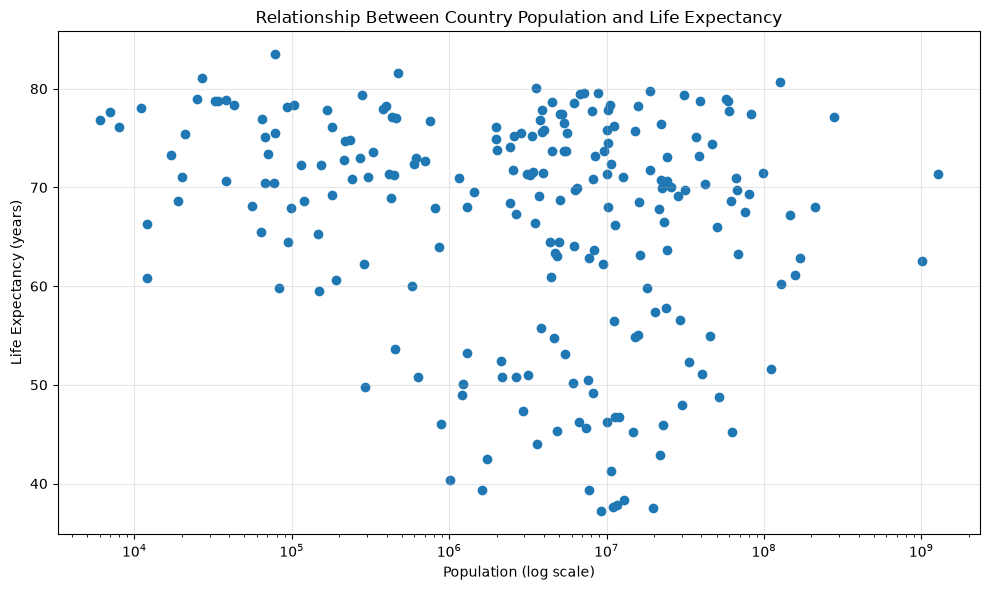

In [7]:
# Create a scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(df["Population"], df["LifeExpectancy"])

plt.xscale("log")
plt.xlabel("Population (log scale)")
plt.ylabel("Life Expectancy (years)")
plt.title("Relationship Between Country Population and Life Expectancy")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In this assignment, I used SQL queries and Python to explore and modify the World database. I identified Palau as the country with the most recent independence year recorded in the original database (1994). I then added South Sudan, which became independent in 2011, to the country table and added its cities, Juba and Wau, to the city table.

For the extra-credit portion, I used SQLAlchemy to retrieve country population and life expectancy data, Pandas to organize the data, and Matplotlib to create a scatter plot examining the relationship between population and life expectancy.

Overall, this assignment provided practice working with relational databases, executing SQL commands through Python, inserting records, retrieving data, and visualizing information.